# Labjournaal BM
## General
**Name:**  
**Title of the experiment:** Bepaling van de constante van Boltzmann  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:** Met de $(I,V)$-karakteristiek van een silicium diode de constante van Boltzmann $k_B$ bepalen. Ook leren werken met DMM's en de spanningsdeler.  
**Research question:** Welke waarde van $k_B$ (met onzekerheid) volgt uit de $(I,V)$-karakteristiek van de diode?  
**Expectations or Hypothesis:** De stroom neemt exponentieel toe met de spanning (een rechte lijn in een semi-log plot). Verwacht wordt dat $k_B$ binnen de onzekerheid gelijk is aan de tabelwaarde $1{,}380649\cdot10^{-23}\,\mathrm{J/K}$.  
**Desired accuracy:** Een onzekerheid in $k_B$ van ongeveer 5 %. Die wordt vooral bepaald door de onzekerheid in $n$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from IPython.display import Markdown, display


# Preparation

**Assignments:**

---
### Opdracht 1 – Nauwkeurigheid en gevoeligheid van een DMM

**a) Nauwkeurigheid.** Specificatie ($10\,\mathrm{V}$-bereik): $\pm(0{,}0015\,\%$ van de aflezing $+\ 0{,}0004\,\%$ van het bereik$)$. Aflezing: $5{,}00000\,\mathrm{V}$.

- aflezing: $0{,}0015\,\% \cdot 5{,}00000\,\mathrm{V} = 75\,\mu\mathrm{V}$
- bereik: $0{,}0004\,\% \cdot 10\,\mathrm{V} = 40\,\mu\mathrm{V}$
- totaal: $75 + 40 = 115\,\mu\mathrm{V}$

Resultaat: $U = 5{,}00000 \pm 0{,}00012\,\mathrm{V}$. De laatste twee cijfers op het display zijn dus niet betrouwbaar.

**b) Gevoeligheid.** Een $4\frac{1}{2}$ digit DMM heeft 20000 tellen. Op het $200\,\mathrm{mV}$-bereik is één tel $200\,\mathrm{mV}/20000 = 10\,\mu\mathrm{V}$. De gevoeligheid is dus $10\,\mu\mathrm{V}$. Bij $9\,\mathrm{mV}$ is dat een relatieve resolutie van ca. $0{,}11\,\%$.

---
### Opdracht 2 – Waarom niet direct meten aan de diode?

**Stroom direct meten werkt slecht:**

- De stroom verandert tussen $0{,}1$ en $0{,}6\,\mathrm{V}$ met ca. 5 decades. Je moet steeds van bereik wisselen, en de kleinste stromen (ca. nA) zijn te klein voor een gewone DMM.
- Een stroommeter heeft een eigen weerstand $R_i$ ($100\,\Omega$–$1\,\mathrm{k}\Omega$ in de laagste bereiken). Bij $U_D \approx 0{,}6\,\mathrm{V}$ is de diodeweerstand maar enkele honderden $\Omega$, dus $R_i$ is even groot als $R_D$. De meter verstoort dan de schakeling en de stroom wordt kleiner.

**Spanning direct over de diode meten werkt slecht:**

- Bij lage spanning is $R_D$ ongeveer $\mathrm{M}\Omega$. De spanningsmeter ($R_i \approx 10\,\mathrm{M}\Omega$) staat parallel aan de diode, en $R_v = \frac{R_D R_i}{R_D + R_i}$ is dan veel kleiner dan $R_D$ (bij $R_D = 10\,\mathrm{M}\Omega$ is $R_v = 5\,\mathrm{M}\Omega$).
- Meet je tegelijk de stroom (in serie) en de spanning (parallel), dan meet de stroommeter ook de stroom door de spanningsmeter. Dat is niet de diodestroom.

---
### Opdracht 3 – Spanningsdeler $330\,\Omega$ en $1000\,\Omega$, $P_{max} = 1\,\mathrm{W}$

- Maximale stroom uit $P = I^2R$: $I_{max} = \sqrt{P/R}$
  - $330\,\Omega$: $\sqrt{1/330} = 55{,}0\,\mathrm{mA}$
  - $1000\,\Omega$: $\sqrt{1/1000} = 31{,}6\,\mathrm{mA}$
- In serie loopt door beide dezelfde stroom, dus de kleinste limiet telt: $I = 31{,}6\,\mathrm{mA}$. Dan is $U_{max} = 0{,}0316 \cdot 1330 \approx 42\,\mathrm{V}$.
- Bij $20\,\mathrm{V}$: $I = 20/1330 = 15{,}04\,\mathrm{mA}$
  - $U_{330} = 15{,}04\,\mathrm{mA} \cdot 330\,\Omega = 4{,}96\,\mathrm{V}$
  - $U_{1000} = 15{,}04\,\mathrm{mA} \cdot 1000\,\Omega = 15{,}04\,\mathrm{V}$ (som $= 20{,}00\,\mathrm{V}$, klopt)

---
### Opdracht 4 – Basisopstelling (diode en $R_1$ in serie, twee spanningsmeters)

- **Spanning over de diode:** de ene voltmeter meet de bronspanning $U_{bron}$, de andere de spanning over $R_1$. Dus $U_D = U_{bron} - U_{R_1}$.
- **Stroom door de diode:** $R_1$ staat in serie met de diode, dus $I_D = U_{R_1}/R_1$. De stroom volgt dus uit een spanningsmeting, zonder stroommeter.
- **Onzekerheden:**

$$u(U_D) = \sqrt{u(U_{bron})^2 + u(U_{R_1})^2} \qquad
\frac{u(I_D)}{I_D} = \sqrt{\left(\frac{u(U_{R_1})}{U_{R_1}}\right)^2 + \left(\frac{u(R_1)}{R_1}\right)^2}$$

  De $u(U)$ komt uit de DMM-specificatie en $u(R_1)$ uit de weerstandsmeting.

---
### Opdracht 5 – Tweede spanningsdeler ($R_2$, $R_3$)

*Aanname (figuur BMopst niet beschikbaar): $R_2$ staat in serie met de bron en $R_3$ staat parallel aan $R_1$ + diode.*

- **Afleiding.** Parallel: $R_p = \dfrac{R_3 (R_1 + R_D)}{R_3 + R_1 + R_D}$. Met $R_2$ als deler geeft dat
$$U = \frac{R_p}{R_2 + R_p}\, U_{bron}.$$
  Als $R_3 \ll R_1 + R_D$, dan is $R_p \approx R_3$ en dus
$$U = \frac{R_3}{R_2 + R_3}\, U_{bron}.$$
- **Voorwaarde $R_3 \ll R_1 + R_D$.** Dan is de stroom door de diodetak veel kleiner dan die door $R_3$, en belast de diodetak de deler niet. De voorwaarde moet ook gelden bij $0{,}6\,\mathrm{V}$, waar $R_D$ het kleinst is (enkele honderden $\Omega$).
- **Extra stap voor $U_D$.** $U$ staat over $R_1$ én de diode samen, dus
$$U_D = U - U_{R_1} = \frac{R_3}{R_2 + R_3}\, U_{bron} - U_{R_1}.$$

---
### Opdracht 6 – Python-script en onzekerheid in $k_B$

Het script staat in de code-cellen hieronder.

**Afleiding van $u(k_B)$.** Uit $k_B = -\dfrac{q}{b\,n\,T}$ (met $q$ exact) volgt

$$\frac{\partial k_B}{\partial b} = -\frac{k_B}{b}, \qquad \frac{\partial k_B}{\partial n} = -\frac{k_B}{n}, \qquad \frac{\partial k_B}{\partial T} = -\frac{k_B}{T}$$

Voor onafhankelijke onzekerheden geldt $u(k_B)^2 = \sum_i \left(\frac{\partial k_B}{\partial x_i}\, u(x_i)\right)^2$, dus

$$u(k_B) = |k_B|\sqrt{\left(\frac{u(b)}{b}\right)^2 + \left(\frac{u(n)}{n}\right)^2 + \left(\frac{u(T)}{T}\right)^2}.$$

**Method:** Diode en $R_1$ in serie, met twee spanningsmeters. Een tweede spanningsdeler ($R_2$, $R_3$) maakt een stabiele lage spanning. Er wordt iteratief gemeten: meting → script → plot → volgende meting.  
**Theory:** $I_D(U_D) = I_0\left(e^{\,b\,U_D} - 1\right)$ met $b = -\dfrac{q}{n k_B T}$, dus $k_B = -\dfrac{q}{b\,n\,T}$. Hier is $q = -1{,}602\cdot10^{-19}\,\mathrm{C}$ (lading van het elektron), zodat $b > 0$.  
**Independent variable:** $U_{bron}$ (en daarmee $U_D$)  
**Dependent variable:** $I_D$  
**Controlled variables:** temperatuur $T$, weerstanden $R_1$, $R_2$, $R_3$, DMM-bereiken  
**Measurement instruments & Settings:** 3½ digit DMM (bronspanning), 5½ digit DMM (spanning over $R_1$ en de weerstandsmetingen)  
**Procedure:**
1. Meet $R_1$, $R_2$ en $R_3$ met de 5½ digit DMM.
2. Bouw de schakeling op: bron → $R_2$, met $R_3$ parallel aan ($R_1$ + diode).
3. Verhoog $U_{bron}$ stapsgewijs. Noteer bij elke stap $U_{bron}$, $U_{R_1}$ en de ingestelde meetbereiken.
4. Draai het script na elke meting. `volgende_meting` laat zien waar nog punten ontbreken.
5. Noteer de temperatuur $T$.

**Setup (drawing or picture):** *(foto of tekening hier invoegen)*  
**Notes:**  
**About accuracy:** De onzekerheid van elke spanning komt uit de DMM-specificatie (% van aflezing + % van bereik + tellen). Die van $R_1$, $R_2$, $R_3$ komt uit de weerstandsmetingen.

In [2]:
# DMM-specificatie als (% van aflezing, % van bereik, aantal tellen, tellen op het volle bereik)
# Deze code is achteraf geschreven. We hadden geen toegang meer tot de meters en kenden de specificaties niet,
# dus zijn dit schattingen zodat we de berekeningen wel konden uitvoeren.
SPEC_35 = (0.5,   0.0,   3, 4000)     # 3 3/4 digit (bereiken 4 V en 40 V)
SPEC_55 = (0.015, 0.003, 0, 200000)   # Siglent SDM3055, 5 1/2 digit

def u_dmm(aflezing, bereik, spec):
    # Onzekerheid van een DMM-meting, in dezelfde eenheid als de aflezing
    pct_aflezing, pct_bereik, tellen, max_tellen = spec
    een_tel = bereik / max_tellen
    return pct_aflezing/100*np.abs(aflezing) + pct_bereik/100*bereik + tellen*een_tel

def lijn(U, b, lnI0):
    # ln(I_D) = b*U_D + ln(I0), zie vergelijking (4)
    return b*U + lnI0

# Execution

In [4]:
# Ruwe data (na elke meting aanvullen).
# U_bron / rng_bron : bronspanning en meetbereik, 3½ digit DMM [V]
# U_R1  / rng_R1    : spanning over R1 en meetbereik, 5½ digit DMM [V]
U_bron   = np.array([2.634,2.794,2.943,3.093,3.243,3.393,3.542,3.692,3.843, 3.992,4.14,4.29,4.44,4.59,4.74,4.89,5.04,5.19,5.33])
rng_bron = np.array([4,4,4,4,4,4,4,4,4,4,4,40,40,40,40,40,40,40,40])
U_R1     = np.array([0.09961, 0.12464,0.14927, 0.17499,0.20144,0.22858,0.25610,0.28412, 0.31259,0.34139,0.37033,0.39955,0.42912,0.45863,0.48854,0.518460,0.54860,0.57874,0.60911])
rng_R1   = np.array([2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2])

# Weerstanden uit de weerstandsmetingen [ohm]. R2 en R3 vormen de tweede deler (zonder tweede deler: R2 = 0).
R1, u_R1 = 997.3, 0.01    # PLACEHOLDER
R2, u_R2 = 328.72, 0.01      # PLACEHOLDER
R3, u_R3 = 100.079, 0.001      # PLACEHOLDER

q = -1.602176634e-19       # lading elektron [C]
T, u_T = 293.15, 1.0       # temperatuur [K], PLACEHOLDER
n, u_n = 2.0, 0.1          # idealiteitsfactor Si (uit de opdrachttekst)

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**
Uit $U_{bron}$ en $U_{R_1}$ worden $U_D$ en $I_D$ uitgerekend (opdracht 4 en 5), inclusief onzekerheden. Daarna wordt een rechte lijn gefit door $\ln I_D$ tegen $U_D$ (vergelijking (4) hieronder). In de fit tellen $u(I_D)$ en $u(U_D)$ allebei mee. Uit de helling $b$ volgt $k_B$.

In [5]:
# Bewerkte data en onzekerheden
u_Ubron = u_dmm(U_bron, rng_bron, SPEC_35)
u_UR1   = u_dmm(U_R1,   rng_R1,   SPEC_55)

deler = R3/(R2+R3)
U_diodetak = U_bron*deler            # spanning over R1 + diode
U_D = U_diodetak - U_R1              # spanning over de diode
I_D = U_R1/R1                        # stroom door de diode

# onzekerheden (kwadratisch optellen)
u_Udiodetak = np.sqrt((deler*u_Ubron)**2
                      + (U_bron*R2/(R2+R3)**2*u_R3)**2
                      + (U_bron*R3/(R2+R3)**2*u_R2)**2)
u_UD = np.sqrt(u_Udiodetak**2 + u_UR1**2)
u_ID = I_D*np.sqrt((u_UR1/U_R1)**2 + (u_R1/R1)**2)


for i in range(len(U_D)):
    print(f"U_D = {U_D[i]:.4f} ± {u_UD[i]:.4f} V    I_D = {I_D[i]:.3e} ± {u_ID[i]:.1e} A")

U_D = 0.5151 ± 0.0038 V    I_D = 9.988e-05 ± 7.5e-08 A
U_D = 0.5275 ± 0.0040 V    I_D = 1.250e-04 ± 7.9e-08 A
U_D = 0.5376 ± 0.0041 V    I_D = 1.497e-04 ± 8.3e-08 A
U_D = 0.5469 ± 0.0043 V    I_D = 1.755e-04 ± 8.6e-08 A
U_D = 0.5555 ± 0.0045 V    I_D = 2.020e-04 ± 9.0e-08 A
U_D = 0.5633 ± 0.0047 V    I_D = 2.292e-04 ± 9.5e-08 A
U_D = 0.5706 ± 0.0048 V    I_D = 2.568e-04 ± 9.9e-08 A
U_D = 0.5776 ± 0.0050 V    I_D = 2.849e-04 ± 1.0e-07 A
U_D = 0.5843 ± 0.0052 V    I_D = 3.134e-04 ± 1.1e-07 A
U_D = 0.5903 ± 0.0054 V    I_D = 3.423e-04 ± 1.1e-07 A
U_D = 0.5959 ± 0.0055 V    I_D = 3.713e-04 ± 1.2e-07 A
U_D = 0.6017 ± 0.0120 V    I_D = 4.006e-04 ± 1.2e-07 A
U_D = 0.6071 ± 0.0122 V    I_D = 4.303e-04 ± 1.2e-07 A
U_D = 0.6126 ± 0.0124 V    I_D = 4.599e-04 ± 1.3e-07 A
U_D = 0.6177 ± 0.0125 V    I_D = 4.899e-04 ± 1.3e-07 A
U_D = 0.6228 ± 0.0127 V    I_D = 5.199e-04 ± 1.4e-07 A
U_D = 0.6277 ± 0.0129 V    I_D = 5.501e-04 ± 1.4e-07 A
U_D = 0.6326 ± 0.0131 V    I_D = 5.803e-04 ± 1.5e-07 A
U_D = 0.63

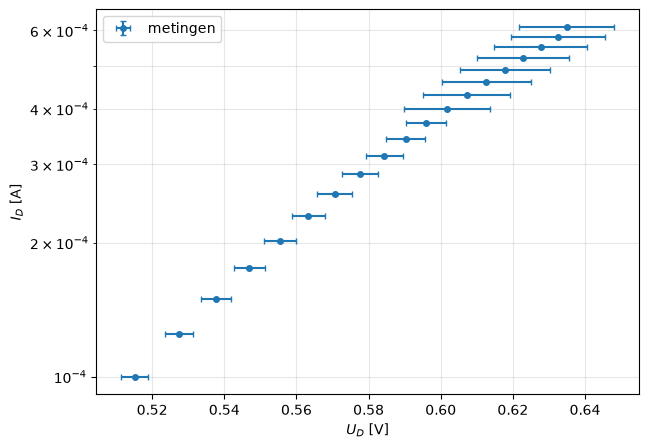

In [6]:
# Plot (semi-log)
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(U_D, I_D, xerr=u_UD, yerr=u_ID, fmt='o', ms=4, capsize=2, label='metingen')
ax.set_yscale('log')
ax.set_xlabel('$U_D$ [V]'); ax.set_ylabel('$I_D$ [A]')
ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.show()

**Waarom een rechte lijn?**
In de semi-log plot liggen de meetpunten (van $U_D \approx 0{,}51$ tot $0{,}64\,\mathrm{V}$) bijna op een rechte lijn. Dat komt doordat de exponent in dit gebied groot is: met $b \approx 15\,\mathrm{V^{-1}}$ geldt $e^{bU_D} \approx e^{8} \approx 3000 \gg 1$. De $-1$ in de diodevergelijking mag je dan weglaten:

$$I_D = I_0\, e^{bU_D}, \qquad b = \frac{-q}{n k_B T} \tag{3}$$

Neem je van beide kanten de natuurlijke logaritme, dan krijg je

$$\ln I_D = b\,U_D + \ln I_0 \tag{4}$$

Dit is een rechte lijn $y = c\,x + d$, met helling $c = b$ en snijpunt $d = \ln I_0$. Uit de helling volgt

$$k_B = \frac{-q}{b\,n\,T}$$

**Onzekerheid in $\ln I_D$.** Voor de fit moeten de onzekerheden ook naar $\ln I_D$ worden omgerekend:

- uit $I_D$: $u(\ln I_D) = u(I_D)/I_D$
- uit $U_D$: een fout $u(U_D)$ verschuift het punt langs de lijn, wat overeenkomt met $b\,u(U_D)$ in $\ln I_D$

Samen geeft dat $u_{tot} = \sqrt{\left(u(I_D)/I_D\right)^2 + \left(b\,u(U_D)\right)^2}$.

b  = 15.62 ± 0.60 1/V
I0 = 3.35e-08 A
chi²_red = 0.19


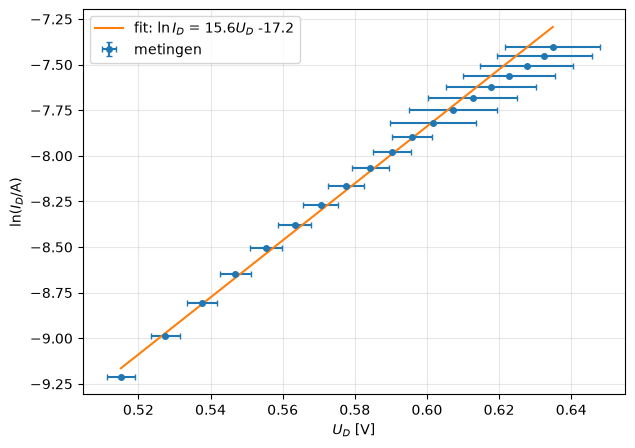

In [7]:
# Fit van een rechte lijn: ln(I_D) = b*U_D + ln(I0)
x = U_D
y = np.log(I_D)

# Stap 1: eerste schatting van b, alleen met de onzekerheid in I_D
u_y = u_ID / I_D
(b, lnI0), cov = curve_fit(lijn, x, y, sigma=u_y, absolute_sigma=True)

# Stap 2: onzekerheid in U_D erbij (die hangt van b af) en opnieuw fitten
u_y = np.sqrt((u_ID/I_D)**2 + (b*u_UD)**2)
(b, lnI0), cov = curve_fit(lijn, x, y, p0=[b, lnI0], sigma=u_y, absolute_sigma=True)
u_b, u_lnI0 = np.sqrt(np.diag(cov))

chi2red = np.sum(((y - lijn(x, b, lnI0))/u_y)**2) / (len(x) - 2)
print(f"b  = {b:.2f} ± {u_b:.2f} 1/V")
print(f"I0 = {np.exp(lnI0):.2e} A")
print(f"chi²_red = {chi2red:.2f}")

# Plot: ln(I_D) tegen U_D met de gefitte rechte lijn
xx = np.linspace(x.min(), x.max(), 100)
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(x, y, xerr=u_UD, yerr=u_ID/I_D, fmt='o', ms=4, capsize=2, label='metingen')
ax.plot(xx, lijn(xx, b, lnI0), label=f'fit: $\\ln I_D$ = {b:.1f}$U_D$ {lnI0:+.1f}')
ax.set_xlabel('$U_D$ [V]'); ax.set_ylabel('$\\ln(I_D / \\mathrm{A})$')
ax.grid(True, alpha=0.3); ax.legend()
plt.show()

**Describing the pattern in the processed data:**
In de semi-log plot liggen de punten bijna op een rechte lijn. De stroom $I_D$ neemt dus exponentieel toe met $U_D$, zoals de diodevergelijking voorspelt. Over het gemeten gebied ($U_D \approx 0{,}51$–$0{,}64\,\mathrm{V}$) loopt de stroom van ongeveer $1\cdot10^{-4}$ tot $6\cdot10^{-4}\,\mathrm{A}$, dus minder dan één decade. Bij de hoogste spanningen liggen de punten iets onder de lijn.

In [8]:
# Eindresultaat: k_B met onzekerheid
kB = -q/(b*n*T)
u_kB = abs(kB)*np.sqrt((u_b/b)**2 + (u_n/n)**2 + (u_T/T)**2)
kB_tabel = 1.380649e-23
verschil = abs(kB - kB_tabel)/u_kB

print(f"k_B = ({kB:.3e} ± {u_kB:.1e}) J/K")
print(f"tabelwaarde = {kB_tabel:.6e} J/K, verschil = {verschil:.1f} x onzekerheid")
print(f"relatieve bijdragen: b {u_b/abs(b):.1%}, n {u_n/n:.1%}, T {u_T/T:.1%}")

k_B = (1.749e-23 ± 1.1e-24) J/K
tabelwaarde = 1.380649e-23 J/K, verschil = 3.3 x onzekerheid
relatieve bijdragen: b 3.9%, n 5.0%, T 0.3%


**Notes:**  